In [4]:
## Bibliotecas importadas:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

## Carregando os dados
dados1 = loadmat('dado1.mat')
X = np.asarray(dados1["X"], dtype=np.float64)
if X.ndim != 2 or X.shape[1] != 32 * 32:
    raise ValueError(f"Esperada matriz (m, 1024); recebido {X.shape}.")

m, p = X.shape
print(f"Imagens: {m} | Pixels por imagem: {p} | Formato: {X.shape}")

Imagens: 5000 | Pixels por imagem: 1024 | Formato: (5000, 1024)


In [ ]:
## Definindo funções auxiliares

def vetor_para_imagem(vetor):
    return np.asarray(vetor).reshape(32, 32).T


def mostrar_grade(dados, linhas=2, colunas=5, titulo="", vmin=None, vmax=None):
    dados = np.asarray(dados)
    fig, axs = plt.subplots(linhas, colunas,
                            figsize=(1.6 * colunas, 1.8 * linhas),
                            squeeze=False, constrained_layout=True)
    for i, ax in enumerate(axs.flat):
        if i < len(dados):
            ax.imshow(vetor_para_imagem(dados[i]), cmap="gray", vmin=vmin, vmax=vmax)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=13)
    plt.show()

In [ ]:
media = X.mean(axis=0)
Xc = X - media

# SVD econômica da matriz centralizada
_, valores_singulares, Vt = np.linalg.svd(Xc, full_matrices=False)
componentes = Vt.T
variancias = valores_singulares**2 / (m - 1)
variancia_total = variancias.sum()
proporcao_variancia = variancias / variancia_total
variancia_acumulada = np.cumsum(proporcao_variancia)

print(f"Formato de X: {X.shape}")
print(f"Componentes principais disponíveis: {componentes.shape[1]}")

Formato de X: (5000, 1024)
Componentes principais disponíveis: 1024


In [6]:
def projetar_reconstruir(dados, k, media_referencia=media, base=componentes):
    vk = base[:, :k]
    z = (np.asarray(dados) - media_referencia) @ vk
    reconstruido = z @ vk.T + media_referencia
    return z, reconstruido

K = 100
Z, X_rec = projetar_reconstruir(X, K)
print(f"Projeção: {Z.shape} | Reconstrução: {X_rec.shape}")

Projeção: (5000, 100) | Reconstrução: (5000, 1024)


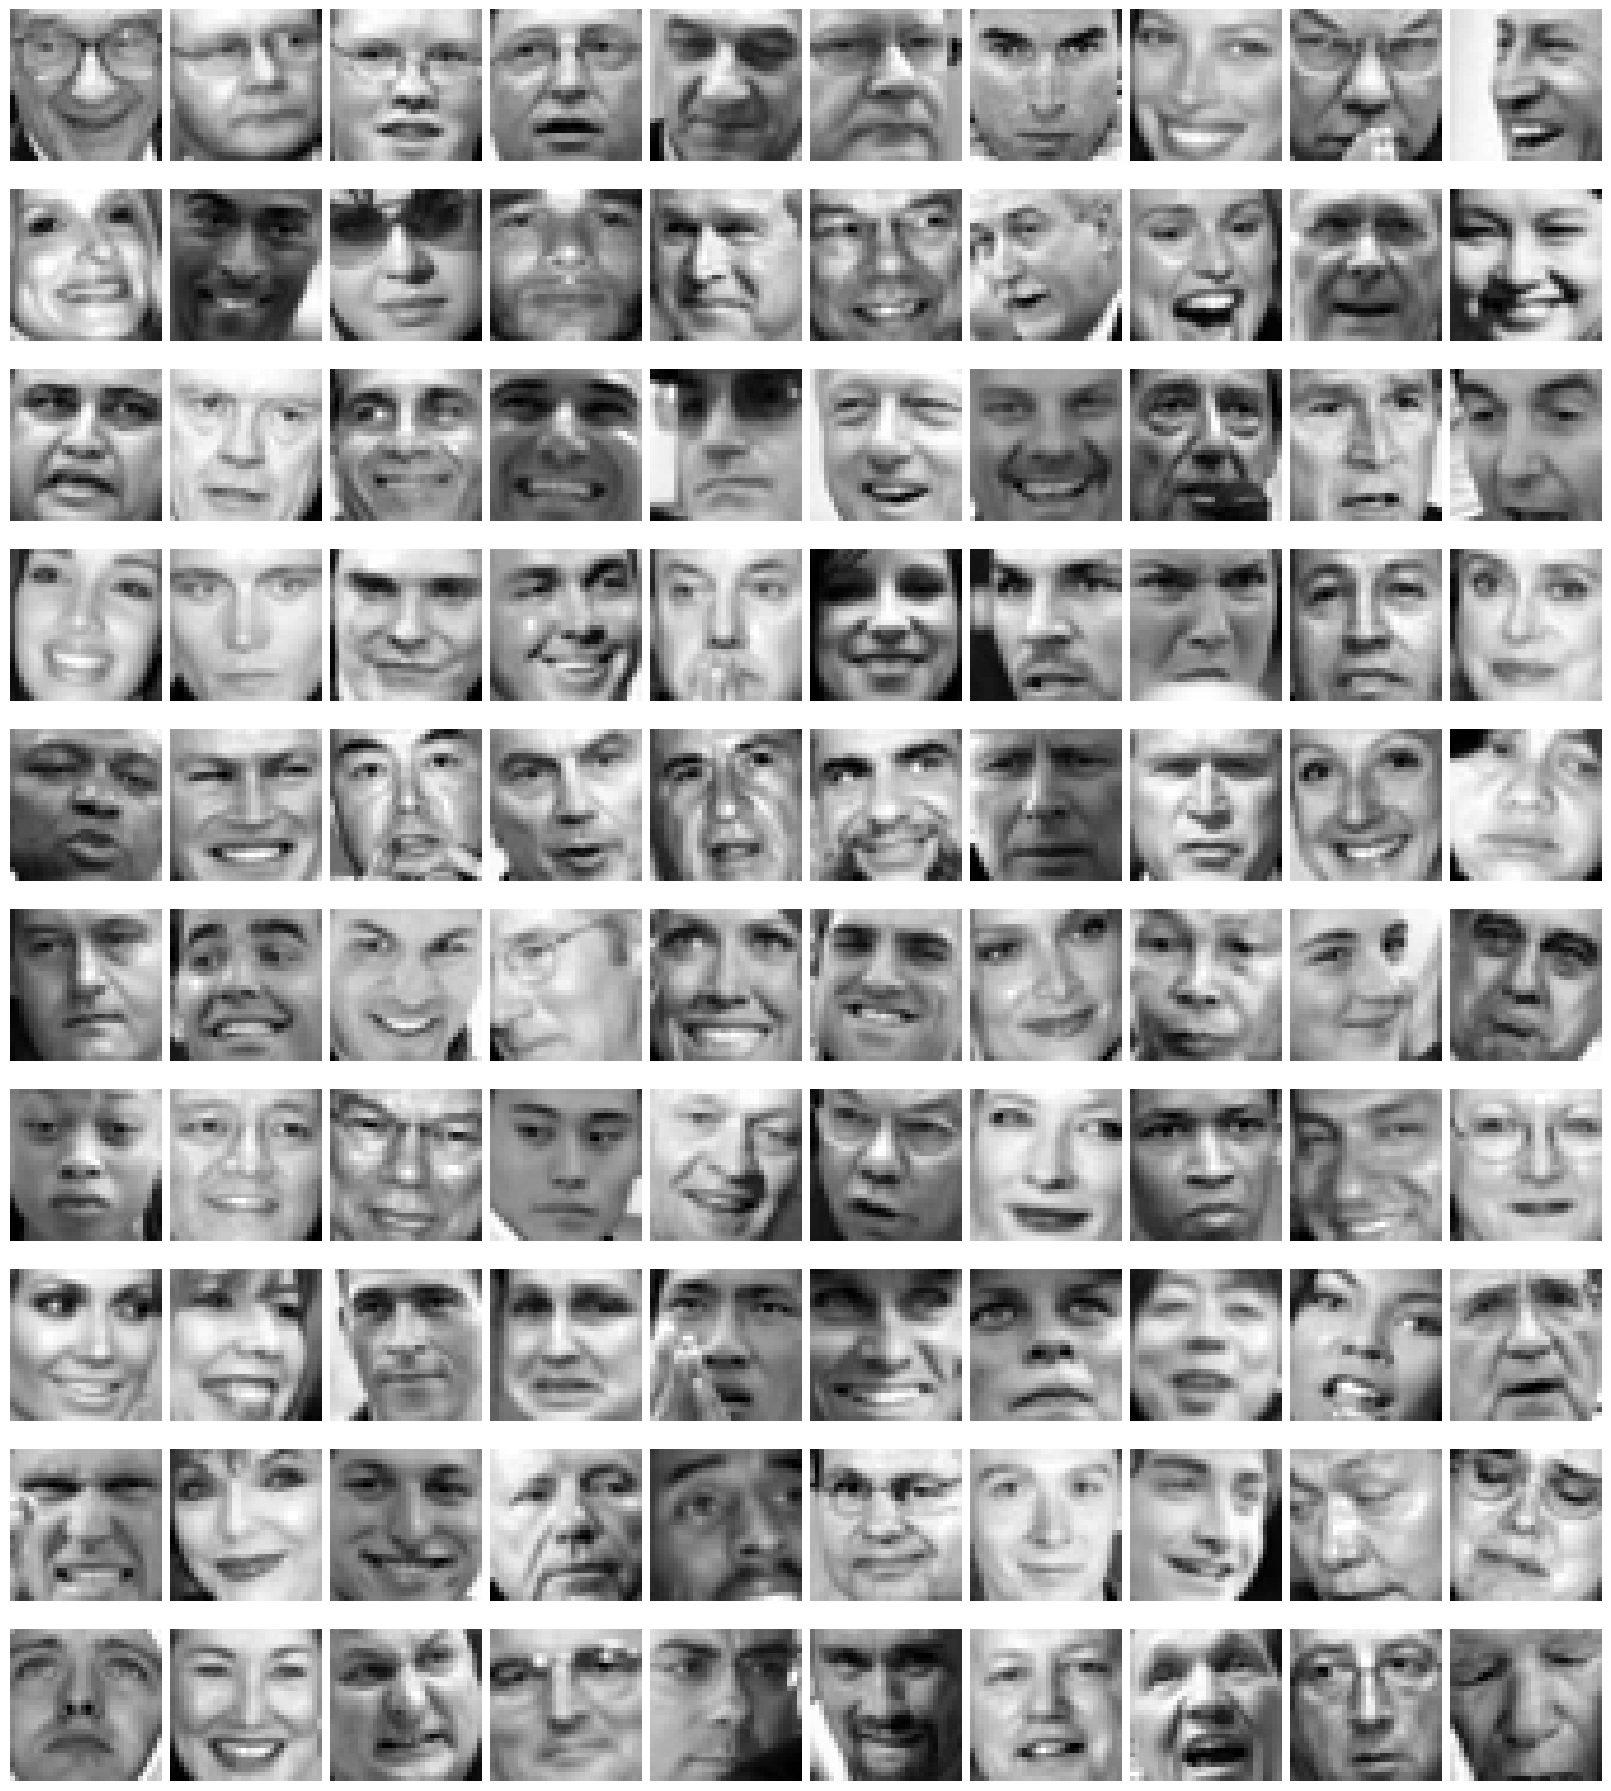

In [ ]:
## 1(a) - 100 rostos quaisquer da base de dados

mostrar_grade(X[:100], linhas=10, colunas=10)

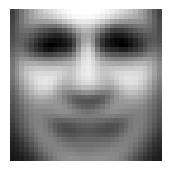

In [ ]:
#Face média (Centralização dos dados)
mostrar_grade(media[None, :], linhas=1, colunas=1)

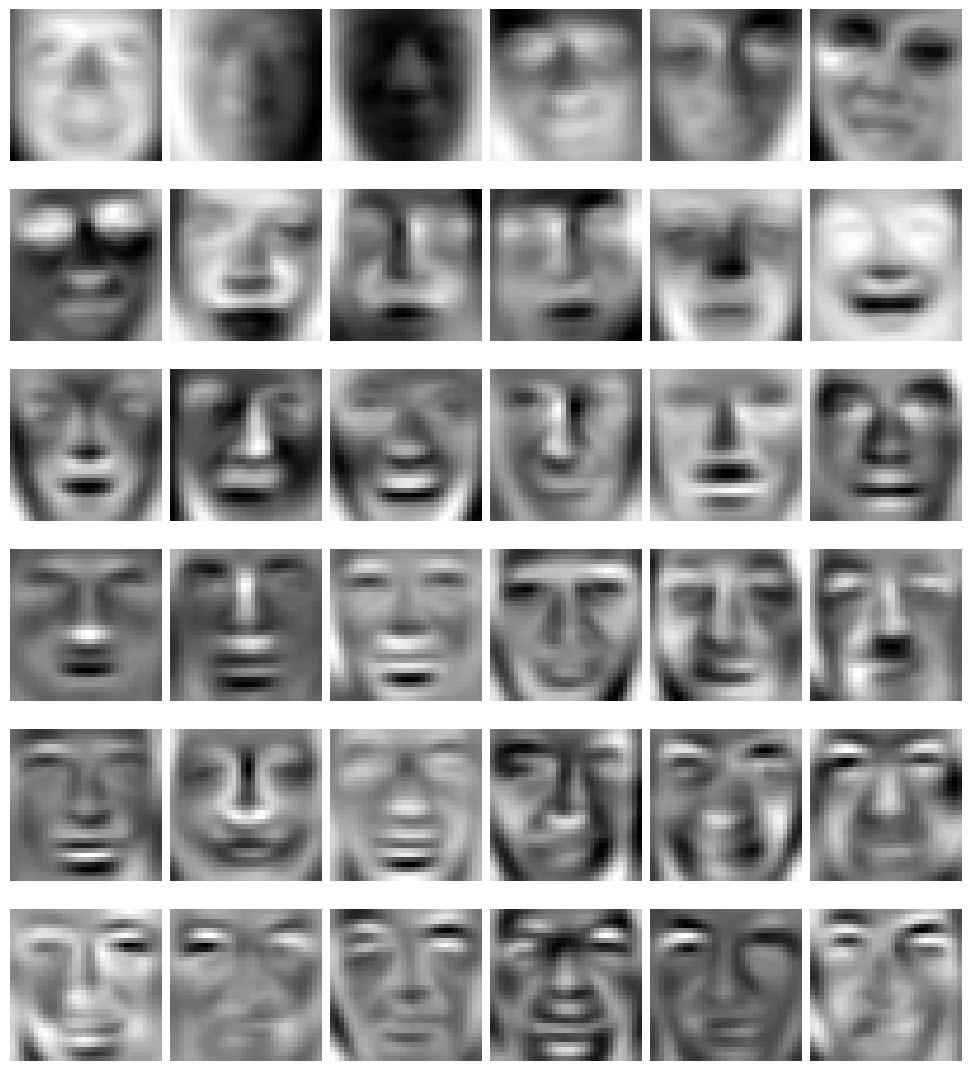

In [ ]:
## 1(b) - Eigenfaces dos primeiros 36 componentes principais
n_eigenfaces = min(36, componentes.shape[1])
mostrar_grade(componentes[:, :n_eigenfaces].T,
             linhas=6, colunas=6)

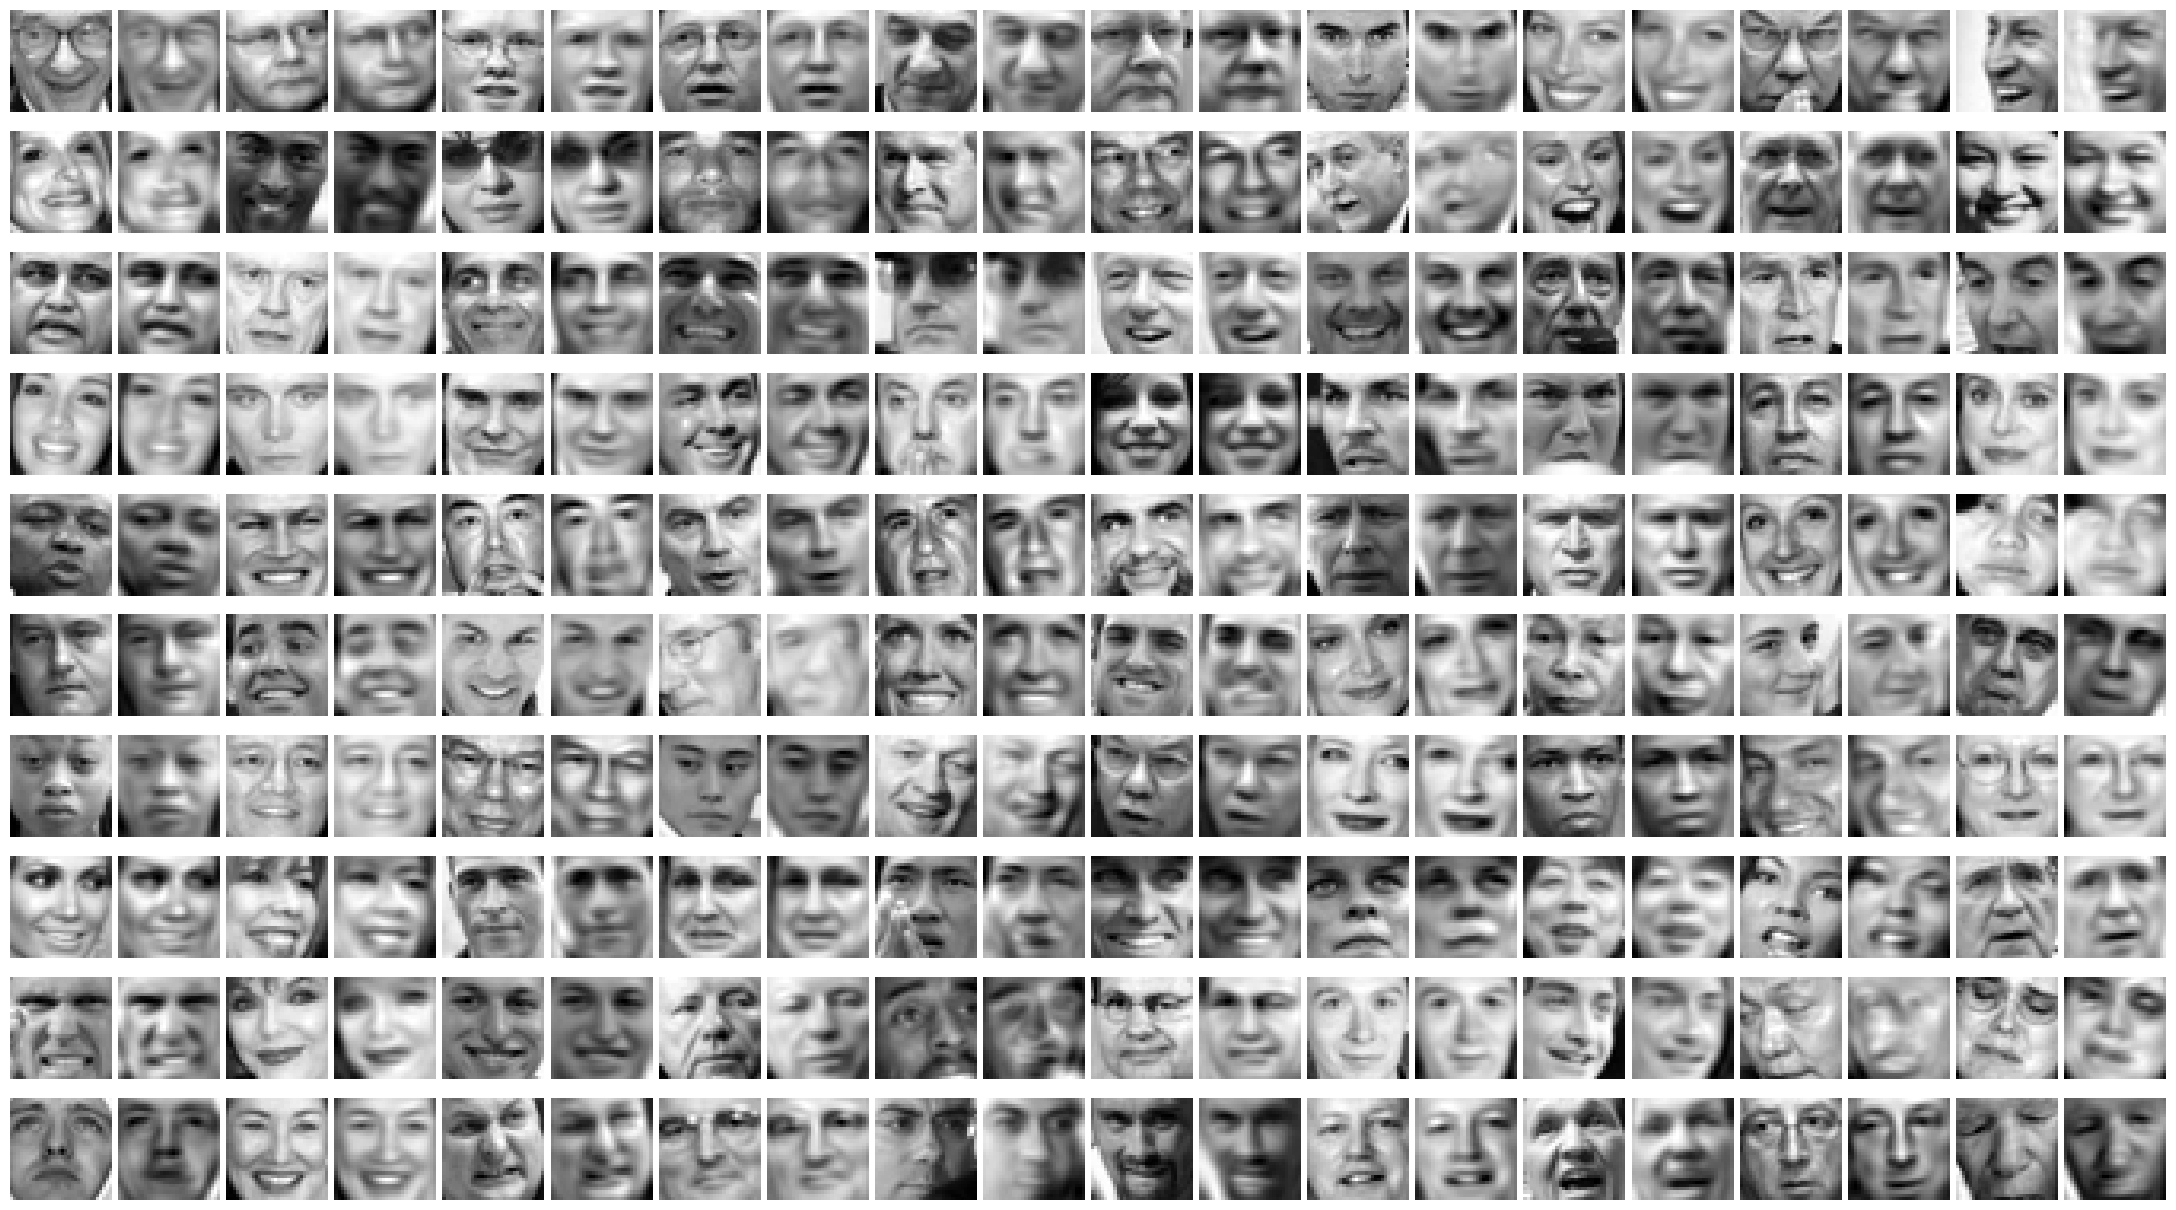

In [ ]:
## 1(c) - Comparação entre imagens originais e reconstruídas

fig, axs = plt.subplots(10, 20, figsize=(22, 13), squeeze=False)
for i in range(100):
    linha = i // 10
    coluna = 2 * (i % 10)
    axs[linha, coluna].imshow(vetor_para_imagem(X[i]), cmap="gray")
    axs[linha, coluna + 1].imshow(vetor_para_imagem(X_rec[i]), cmap="gray")
    axs[linha, coluna].axis("off")
    axs[linha, coluna + 1].axis("off")

fig.subplots_adjust(left=0.01, right=0.99, top=0.94, bottom=0.02, wspace=0.06, hspace=0.12)
plt.show()

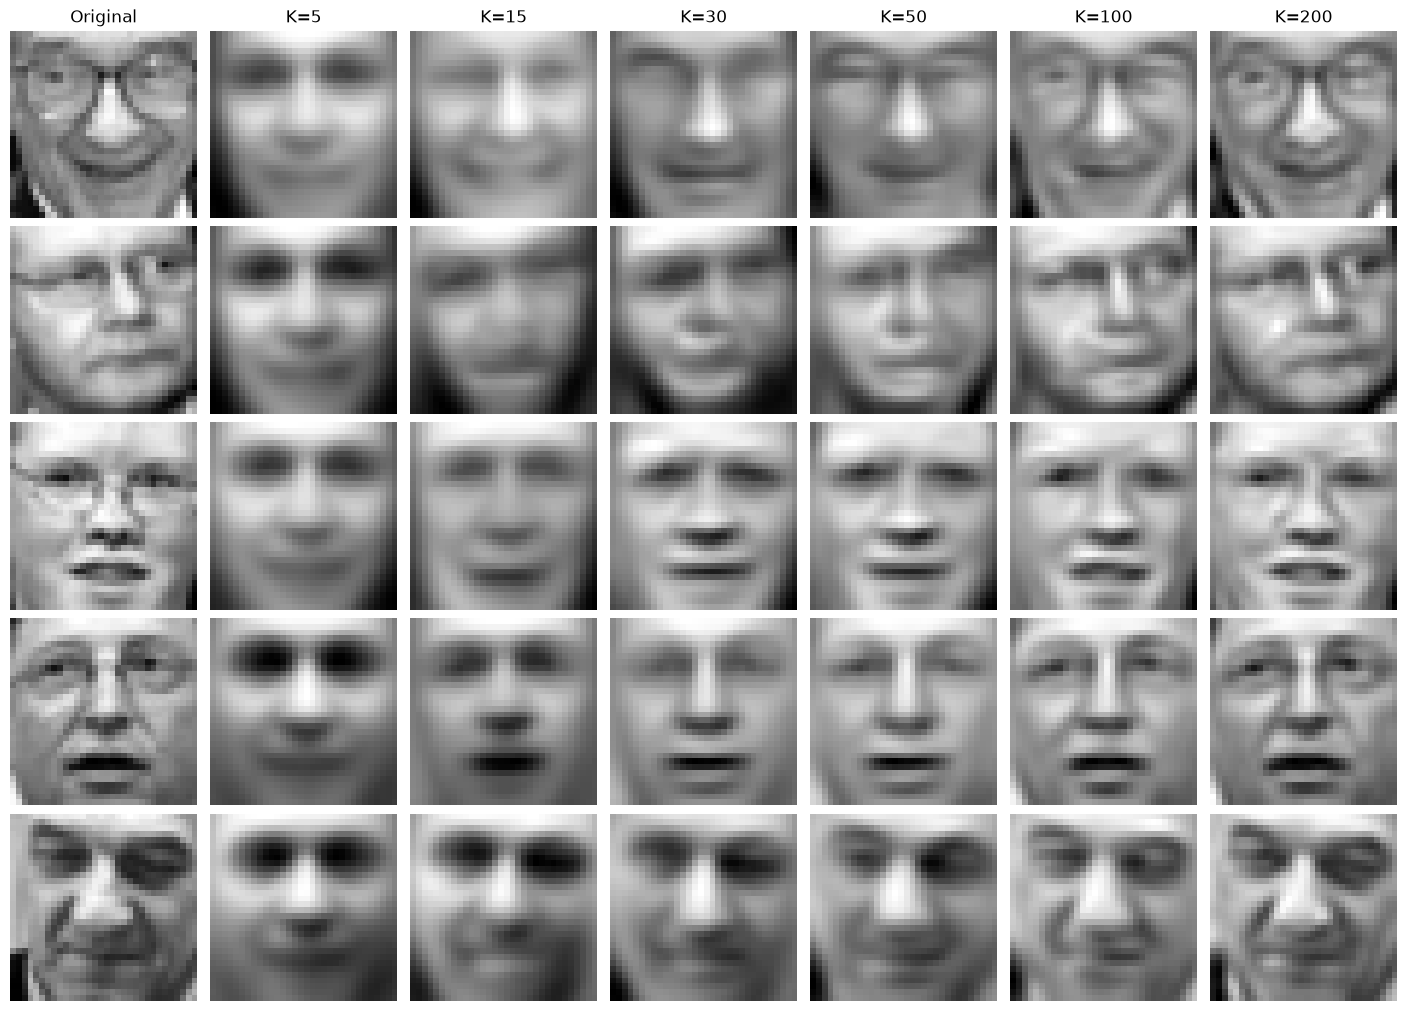

In [ ]:
## Reconstrução com diferentes valores de K

ks_comparacao = sorted(set(min(k, componentes.shape[1]) for k in (5, 15, 30, 50, 100, 200)))
indices_exemplo = list(range(min(5, m)))
fig, axs = plt.subplots(len(indices_exemplo), len(ks_comparacao) + 1,
                        figsize=(2 * (len(ks_comparacao) + 1), 2 * len(indices_exemplo)),
                        squeeze=False, constrained_layout=True)
for i, idx in enumerate(indices_exemplo):
    axs[i, 0].imshow(vetor_para_imagem(X[idx]), cmap="gray")
    axs[i, 0].axis("off")
for j, k in enumerate(ks_comparacao, start=1):
    _, reconstruidas = projetar_reconstruir(X[indices_exemplo], k)
    for i in range(len(indices_exemplo)):
        axs[i, j].imshow(vetor_para_imagem(reconstruidas[i]), cmap="gray")
        axs[i, j].axis("off")
for j, nome in enumerate(["Original"] + [f"K={k}" for k in ks_comparacao]):
    axs[0, j].set_title(nome)
plt.show()

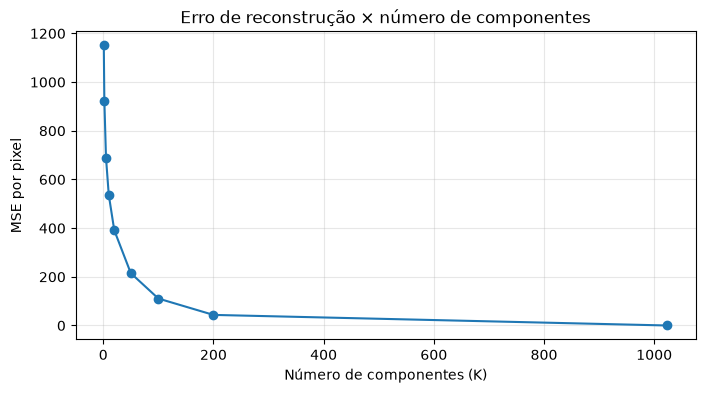

   K | Variância retida | MSE por pixel
   1 |          30.27% | 1150.33
   2 |          43.98% | 924.222
   5 |          58.22% | 689.336
  10 |          67.44% | 537.141
  20 |          76.28% | 391.303
  50 |          86.97% | 215.001
 100 |          93.29% | 110.765
 200 |          97.36% | 43.5239
1024 |         100.00% | 0


In [ ]:
### Erro de reconstrução em função de K

ks_erro = sorted(set([1, 2, 5, 10, 20, 50, 100, 200, componentes.shape[1]]))
ks_erro = [k for k in ks_erro if k <= componentes.shape[1]]


erros = [float(np.sum(valores_singulares[k:] ** 2) / X.size) for k in ks_erro]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks_erro, erros, marker="o")
ax.set(xlabel="Número de componentes (K)", ylabel="MSE por pixel",
       title="Erro de reconstrução × número de componentes")
ax.grid(alpha=0.3)
plt.show()

print("   K | Variância retida | MSE por pixel")
for k, erro in zip(ks_erro, erros):
    print(f"{k:4d} | {variancia_acumulada[k-1]:15.2%} | {erro:.6g}")